# Инференс SVD-SNO на других FEM-сетках

Проверяем **сохранённые low-band и high-band randomized SVD-SNO модели** на других триангуляциях той же области и той же фиксированной среды №0. Обучающая сетка: 3221 узел, `h=0.1`. Для каждой полосы берём три test-частоты и два направления на частоту. Ни одна из этих частот не входила в обучение.

Веса, нормировка и исходные POD-базисы сохраняются. Среднее и моды вычисляются в новых узлах барицентрическим переносом по исходным треугольникам. Это позволяет получать поле на новой сетке, но сохраняет разрешение исходного выученного пространства.

Notebook выполняется локально в окружении **DOLFINx Complex**, в новом ядре после обучения SVD-SNO. Заново обучать модели или загружать все 8000 полей в память не требуется. FEM вызывается только для независимой оценки предсказаний.

Выводим Re(u_scattering), Im(u_scattering), Abs(u_scattering) на целевых узлах. Модуль вычисляется **после** переноса Re и Im; перенос готового модуля в общем случае даёт другую величину. На рисунках для каждой компоненты показаны независимый FEM, модель и абсолютные различия поля между сетками и модели с целевым FEM.


In [ ]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'neural_operator').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from neural_operator.randomized import settings
from neural_operator.mesh_study import run_cross_mesh_study
from neural_operator.training import load_predictor
from neural_operator.plotting import display_table
from neural_operator.fields import scattering_components
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri


In [2]:
CHECKPOINTS = {
    'low': settings.LOW_RUNS / 'svd' / 'model.pt',
    'high': settings.HIGH_RUNS / 'svd' / 'model.pt',
}
DATASETS = {'low': settings.LOW_DATA_DIR, 'high': settings.HIGH_DATA_DIR}
OUT = settings.BASE / 'runs' / 'cross_mesh'
N_FREQUENCIES, N_DIRECTIONS = 3, 2
MESH_SPECS = {
    'coarse': {'h': 0.2, 'n_coarse': 4},
    'retriangulated': {'h': 0.1, 'n_coarse': 3},
    'fine': {'h': 0.05, 'n_coarse': 4},
}
for band, checkpoint in CHECKPOINTS.items():
    if not checkpoint.is_file():
        raise FileNotFoundError(f'{checkpoint}: сначала выполните sno/Randomized-SVD.ipynb для полосы {band}')
print('Обучение: 0 эпох. Пересчитываем FEM только для выбранных test-запросов.')
print('Результаты:', OUT)


Обучение: 0 эпох. Пересчитываем FEM только для выбранных test-запросов.
Результаты: /workspace/multiscale-fem-scattering/neural_operator/randomized/runs/cross_mesh


## Протокол и метрики

Сравниваем грубую сетку, сетку другой связности при том же `h`, мелкую сетку и перестановку узлов обучающей сетки. `n_coarse` меняет вспомогательное разбиение, форма включений остаётся той же. Материалы DG0 назначаются по физическим меткам кругов, без интерполяции через границы материалов. На каждой новой сетке независимо решается та же задача Гельмгольца для тех же `(k,θ)`; для перестановки достаточно переставить исходный эталон.

Для каждого запроса считаем комплексную относительную FEM L2-ошибку с **consistent mass matrix целевой сетки**:

- **Модель / target FEM** — итоговая точность на новой сетке.
- **Source FEM → target / target FEM** — расхождение дискретизаций вместе с переносом исходного эталона.
- **Модель / перенесённый source FEM** — ошибка модели относительно её исходного эталона после переноса.

Дополнительно проверяем roundtrip исходного FEM-поля и равенство переноса мод переносу готового предсказания. Эти относительные ошибки имеют разные знаменатели; складывать их проценты нельзя. Три частоты на полосу — небольшой тест переноса, а не оценка на всех 1280 test-полях.

Значения для исходной сетки здесь относятся к тем же шести запросам. Ранее полученные **0.96% / 5.54%** относятся ко всем 1280 test-полям low/high; выборки различаются, checkpoint остаются прежними.


In [3]:
rows, summaries, fields, mesh_info = run_cross_mesh_study(
    CHECKPOINTS, DATASETS, OUT,
    n_frequencies=N_FREQUENCIES, n_directions=N_DIRECTIONS,
    mesh_specs=MESH_SPECS,
)
metadata = json.loads(fields['metadata_json'].item())
assert len(rows) == 2 * 4 * N_FREQUENCIES * N_DIRECTIONS
assert all(record['unchanged'] for record in metadata['checkpoints'].values())
assert metadata['training_epochs'] == 0 and not metadata['refit']
for info in mesh_info.values():
    for mapping in info['mapping_by_band'].values():
        for direction in ('forward', 'reverse'):
            assert mapping[direction]['coverage'] == 1.0
            assert mapping[direction]['max_abs_rowsum_minus_one'] < 1e-12
print('Завершено:', len(rows), 'сравнений; checkpoint SHA256 до/после совпадают.')
display_table([{'mesh': name, 'nodes': info['nodes'], 'triangles': info['triangles']}
               for name, info in mesh_info.items()])


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/randomized/runs/cross_mesh/meshes/coarse/etal.msh'...
Info    : 175 entities
Info    : 1636 nodes
Info    : 3270 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/randomized/runs/cross_mesh/meshes/coarse/etal.msh'


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/randomized/runs/cross_mesh/meshes/retriangulated/etal.msh'...
Info    : 184 entities
Info    : 3274 nodes
Info    : 6546 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/randomized/runs/cross_mesh/meshes/retriangulated/etal.msh'


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/randomized/runs/cross_mesh/meshes/fine/etal.msh'...
Info    : 175 entities
Info    : 8958 nodes
Info    : 17914 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/randomized/runs/cross_mesh/meshes/fine/etal.msh'


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_low_frequency_1000x8/etal.msh'...
Info    : 175 entities
Info    : 3221 nodes
Info    : 6440 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_low_frequency_1000x8/etal.msh'


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_high_frequency_1000x8/etal.msh'...
Info    : 175 entities
Info    : 3221 nodes
Info    : 6440 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_high_frequency_1000x8/etal.msh'


Завершено: 48 сравнений; checkpoint SHA256 до/после совпадают.


mesh,nodes,triangles
coarse,1636,3190
retriangulated,3274,6378
fine,8958,17594
permuted,3221,6280


In [4]:
query_rows = []
for band in CHECKPOINTS:
    for row in rows:
        if row['band'] == band and row['mesh'] == 'permuted':
            query_rows.append({key: row[key] for key in
                               ('band', 'sample_index', 'frequency_id', 'k0', 'theta')})
display_table(query_rows)


band,sample_index,frequency_id,k0,theta
low,8,1,1.001,0.033124
low,10,1,1.001,1.6039
low,4488,561,1.5616,0.40121
low,4490,561,1.5616,1.972
low,7904,988,1.989,0.39765
low,7906,988,1.989,1.9684
high,8,1,4.004,0.033124
high,10,1,4.004,1.6039
high,4488,561,6.2462,0.40121
high,4490,561,6.2462,1.972


In [5]:
ORDER = ['permuted', 'coarse', 'retriangulated', 'fine']
LABELS = {'permuted': 'Исходная: перестановка', 'coarse': 'Грубая h=0.2',
          'retriangulated': 'Другая h=0.1', 'fine': 'Мелкая h=0.05'}
summary_table = []
for band in CHECKPOINTS:
    for mesh in ORDER:
        r = next(item for item in summaries if item['band'] == band and item['mesh'] == mesh)
        summary_table.append({
            'band': band, 'mesh': mesh, 'cases': r['cases'],
            'model / target FEM, %': 100*r['error_model_vs_target_fem_mean'],
            'source FEM → target / target FEM, %': 100*r['error_source_fem_vs_target_fem_mean'],
            'model / transferred source FEM, %': 100*r['error_model_vs_transferred_source_fem_mean'],
            'max model / target FEM, %': 100*r['error_model_vs_target_fem_max'],
        })
display_table(summary_table)


band,mesh,cases,"model / target FEM, %","source FEM → target / target FEM, %","model / transferred source FEM, %","max model / target FEM, %"
low,permuted,6,1.6029,6.2821e-16,1.6029,2.948
low,coarse,6,1.7588,0.78044,1.6056,2.9486
low,retriangulated,6,1.6281,0.33253,1.6019,2.9309
low,fine,6,1.7133,0.52765,1.6024,2.9934
high,permuted,6,10.326,7.8744e-16,10.326,14.913
high,coarse,6,20.744,17.384,10.214,28.358
high,retriangulated,6,10.865,2.6178,10.3,15.394
high,fine,6,14.604,7.7895,10.323,24.074


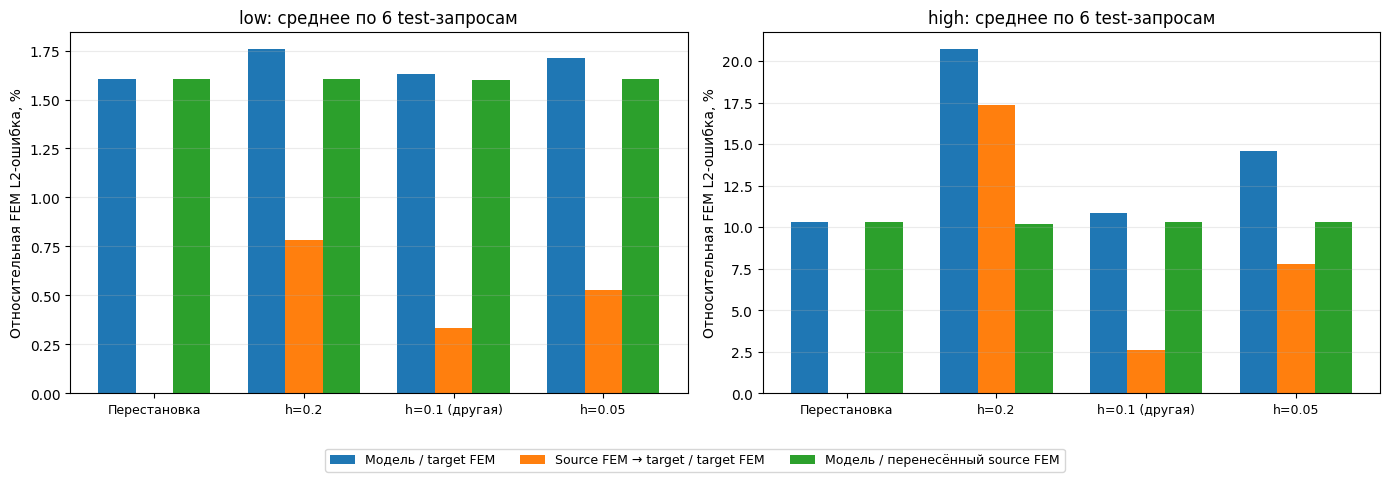

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
metrics = [
    ('error_model_vs_target_fem_mean', 'Модель / target FEM'),
    ('error_source_fem_vs_target_fem_mean', 'Source FEM → target / target FEM'),
    ('error_model_vs_transferred_source_fem_mean', 'Модель / перенесённый source FEM'),
]
x, width = np.arange(len(ORDER)), 0.25
short_labels = ['Перестановка', 'h=0.2', 'h=0.1 (другая)', 'h=0.05']
for ax, band in zip(axes, CHECKPOINTS):
    group = {r['mesh']: r for r in summaries if r['band'] == band}
    for j, (metric, label) in enumerate(metrics):
        ax.bar(x+(j-1)*width, [100*group[name][metric] for name in ORDER],
               width, label=label)
    ax.set_xticks(x, short_labels)
    ax.tick_params(axis='x', labelsize=9)
    ax.set(title=f'{band}: среднее по 6 test-запросам', ylabel='Относительная FEM L2-ошибка, %')
    ax.grid(axis='y', alpha=0.25)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=9)
fig.tight_layout(rect=(0, 0.09, 1, 1))
fig.savefig(OUT / 'errors_by_mesh.png', dpi=160)
plt.show()


## Проверка корректности переноса

Перестановка узлов должна сохранять предсказание и FEM-поле. На разных триангуляциях обратный перенос обычно теряет часть информации: ненулевой roundtrip сам по себе не означает ошибку кода. Равенство `T(mean + modes @ c) = T(mean) + T(modes) @ c` проверяется отдельно; здесь допустимо только округление float32.


In [7]:
checks = []
for r in summaries:
    checks.append({
        'band': r['band'], 'mesh': r['mesh'],
        'mean source model error, %': 100*r['source_model_vs_source_fem_mean'],
        'mean source FEM roundtrip, %': 100*r['roundtrip_source_fem_mean'],
        'max transfer/decode relative difference': r['commutation_error_relative_max'],
    })
    assert r['commutation_error_relative_max'] < 2e-6
    if r['mesh'] == 'permuted':
        assert r['error_source_fem_vs_target_fem_max'] < 1e-11
        assert r['roundtrip_source_fem_max'] < 1e-11
        np.testing.assert_allclose(r['error_model_vs_target_fem_mean'],
                                   r['source_model_vs_source_fem_mean'], rtol=2e-5, atol=1e-8)
display_table(checks)
print('Проверки переноса пройдены; обучения и fit target-полей нет.')


band,mesh,"mean source model error, %","mean source FEM roundtrip, %",max transfer/decode relative difference
low,coarse,1.6029,0.91251,7.5018e-08
low,retriangulated,1.6029,0.51754,8.5323e-08
low,fine,1.6029,0.31929,8.8545e-08
low,permuted,1.6029,1.3315e-15,7.0556e-18
high,coarse,10.326,8.3753,1.3976e-07
high,retriangulated,10.326,4.2612,1.5861e-07
high,fine,10.326,1.9434,1.5816e-07
high,permuted,10.326,1.614e-15,8.7893e-18


Проверки переноса пройдены; обучения и fit target-полей нет.


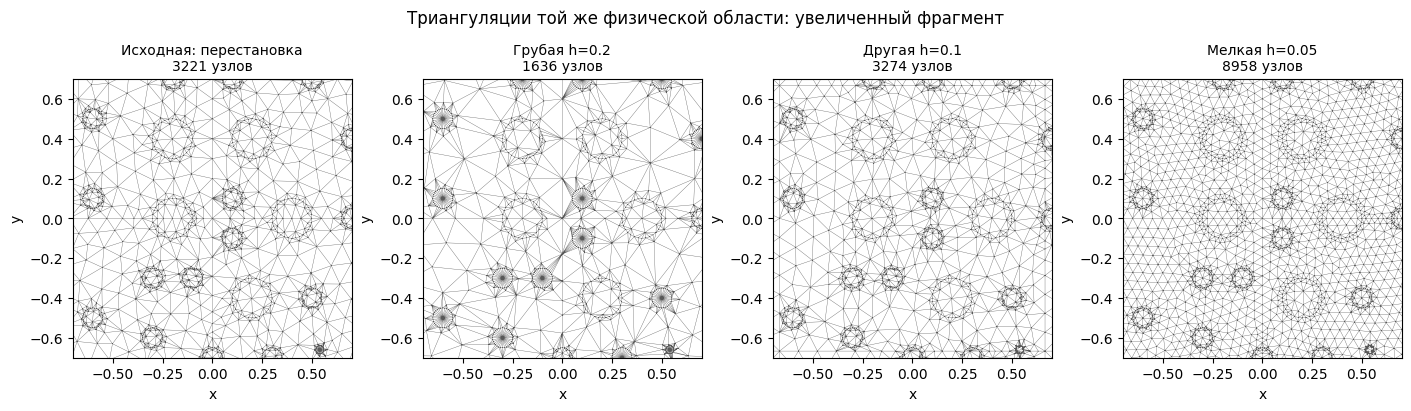

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4), constrained_layout=True)
for ax, name in zip(axes, ORDER):
    prefix = f'low__{name}'
    xy, tri = fields[prefix+'__coordinates'], fields[prefix+'__triangles']
    ax.triplot(xy[:,0], xy[:,1], tri, lw=0.25, color='0.35')
    ax.set(xlim=(-0.7, 0.7), ylim=(-0.7, 0.7), aspect='equal',
           xlabel='x', ylabel='y', title=f'{LABELS[name]}\n{len(xy)} узлов')
    ax.title.set_fontsize(10)
fig.suptitle('Триангуляции той же физической области: увеличенный фрагмент', fontsize=12)
fig.savefig(OUT / 'target_meshes.png', dpi=160)
plt.show()


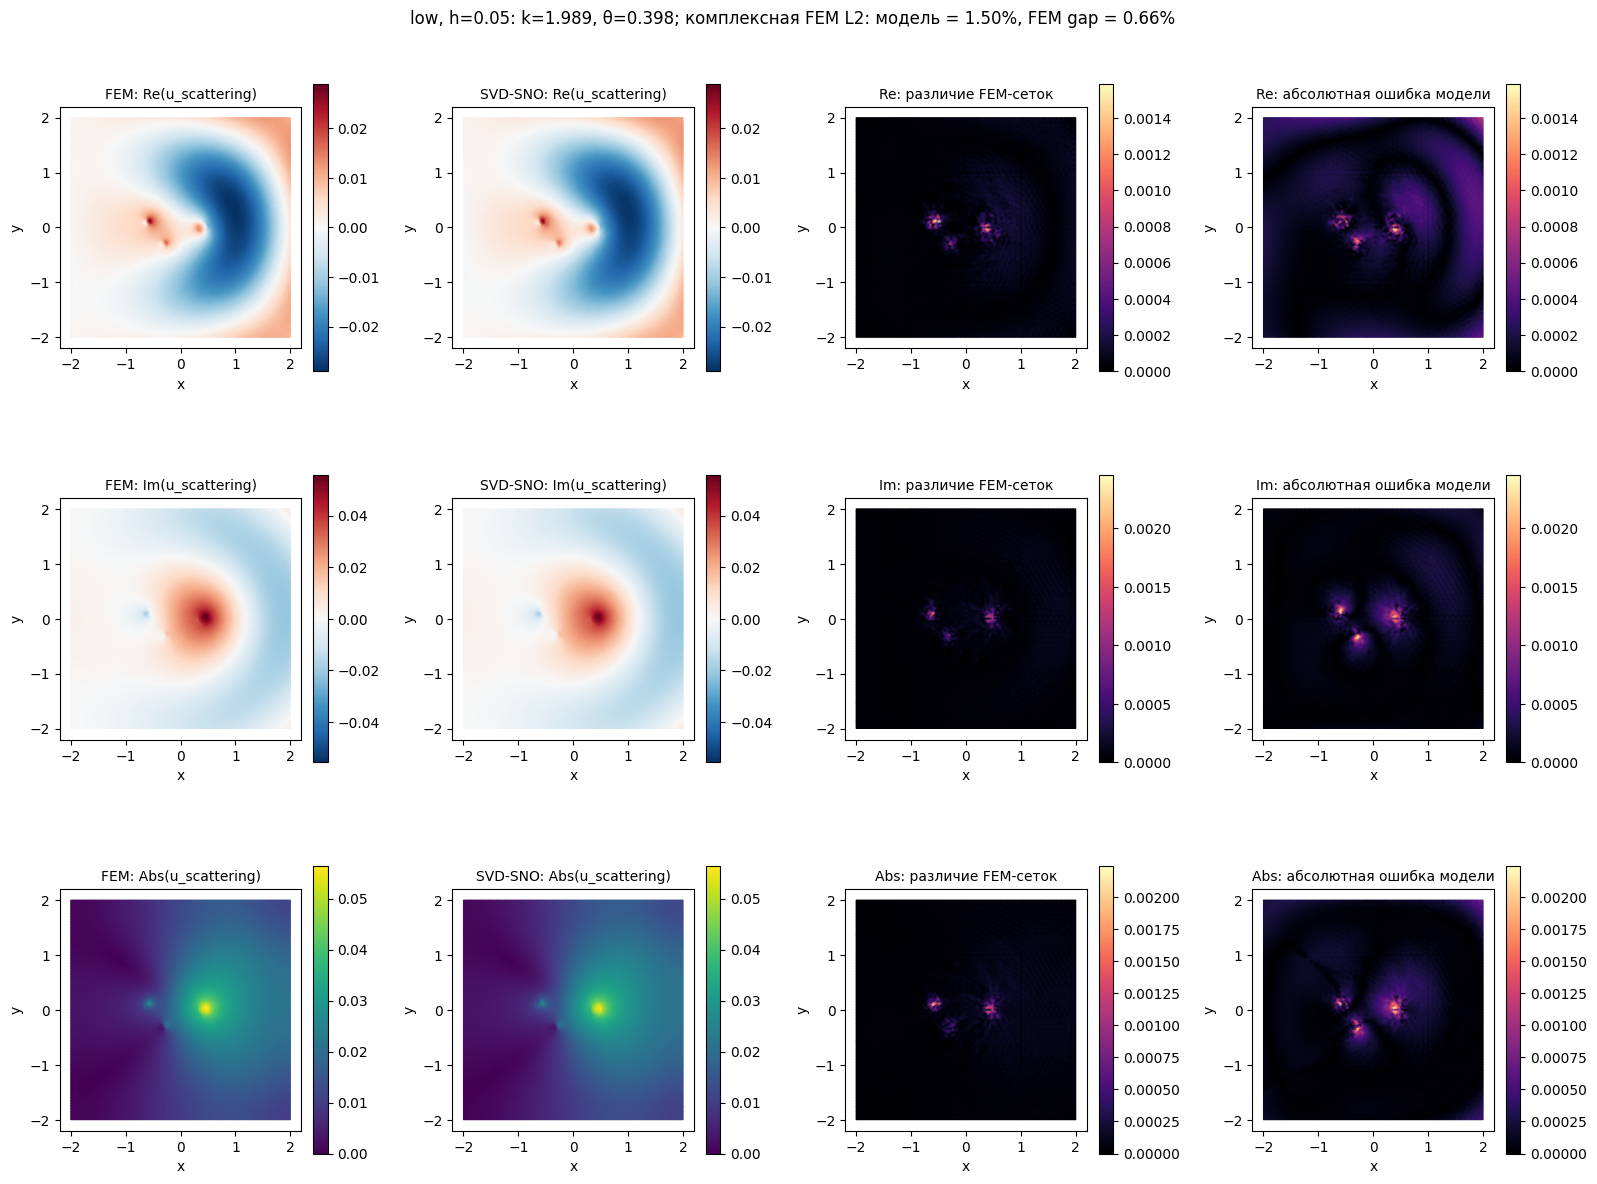

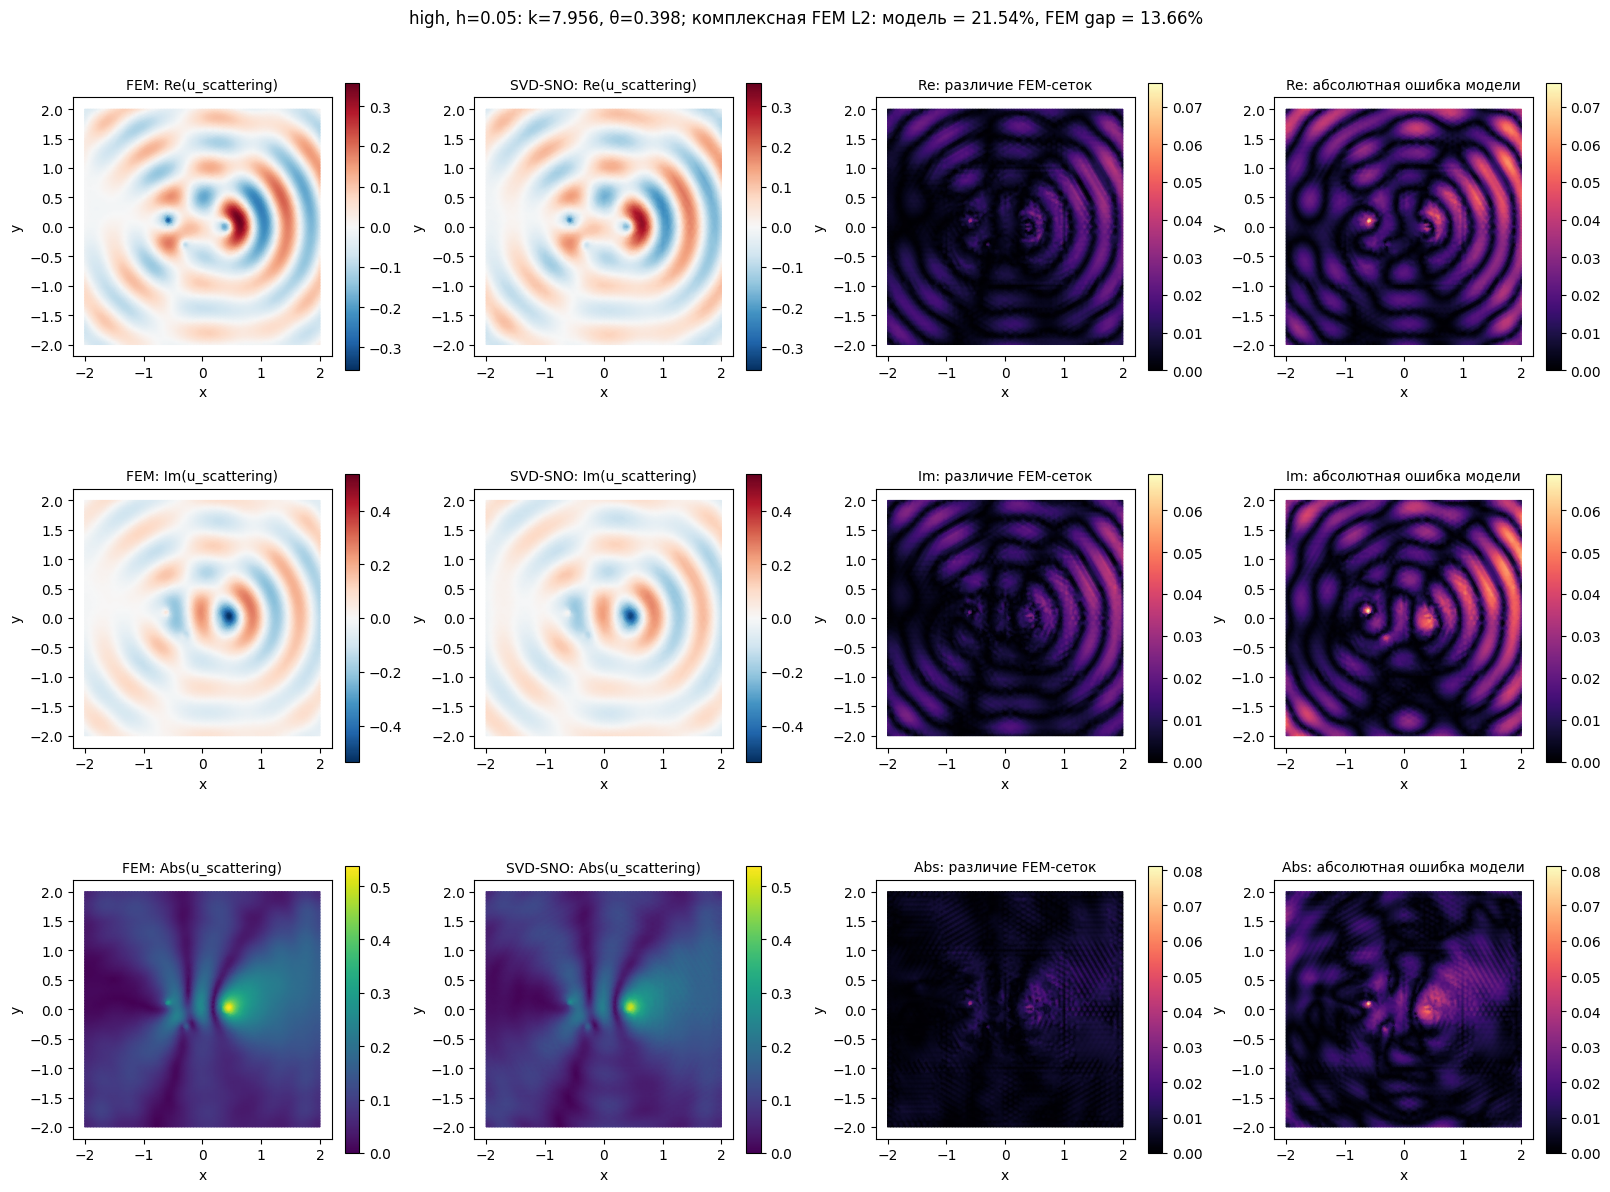

In [ ]:
def plot_fine_case(band):
    prefix = f'{band}__fine'
    xy, tri = fields[prefix+'__coordinates'], fields[prefix+'__triangles']
    ks = fields[prefix+'__k0']
    j = int(np.flatnonzero(ks == ks.max())[0])
    reference = scattering_components(fields[prefix+'__reference'][j])
    prediction = scattering_components(fields[prefix+'__prediction'][j])
    transferred = scattering_components(fields[prefix+'__source_fem_transferred'][j])
    angle = float(fields[prefix+'__theta'][j])
    sample = int(fields[prefix+'__sample_indices'][j])
    r = next(r for r in rows if r['band'] == band and r['mesh'] == 'fine'
             and r['sample_index'] == sample)
    triangulation = mtri.Triangulation(xy[:,0], xy[:,1], tri)
    fig, axes = plt.subplots(3, 4, figsize=(16, 12), constrained_layout=True)
    for row_axes, key, label in zip(axes, ['real', 'imag', 'abs'], ['Re', 'Im', 'Abs']):
        ref, pred, moved = reference[key], prediction[key], transferred[key]
        limit = max(float(np.abs(ref).max()), float(np.abs(pred).max()), 1e-12)
        field_cmap, lower = ('viridis', 0) if key == 'abs' else ('RdBu_r', -limit)
        model_error, mesh_gap = np.abs(pred-ref), np.abs(moved-ref)
        error_limit = max(float(model_error.max()), float(mesh_gap.max()), 1e-12)
        panels = [
            (ref, f'FEM: {label}(u_scattering)', field_cmap, lower, limit),
            (pred, f'SVD-SNO: {label}(u_scattering)', field_cmap, lower, limit),
            (mesh_gap, f'{label}: различие FEM-сеток', 'magma', 0, error_limit),
            (model_error, f'{label}: абсолютная ошибка модели', 'magma', 0, error_limit),
        ]
        for ax, (value, title, cmap, lo, hi) in zip(row_axes, panels):
            artist = ax.tripcolor(triangulation, value, shading='gouraud', cmap=cmap, vmin=lo, vmax=hi)
            ax.set(title=title, aspect='equal', xlabel='x', ylabel='y')
            ax.title.set_fontsize(10)
            fig.colorbar(artist, ax=ax, shrink=0.75)
    fig.suptitle(f'{band}, h=0.05: k={ks[j]:.3f}, θ={angle:.3f}; '
                 f'комплексная FEM L2: модель = {100*r["error_model_vs_target_fem"]:.2f}%, '
                 f'FEM gap = {100*r["error_source_fem_vs_target_fem"]:.2f}%', fontsize=12)
    fig.savefig(OUT / f'{band}_fine_fields.png', dpi=160)
    return fig

for band in CHECKPOINTS:
    plot_fine_case(band)
    plt.show()


## Самостоятельный запрос на новой сетке

После эксперимента FEM solver и обучающий датасет не нужны: достаточно checkpoint и координат новых узлов. Для текущей фиксированной среды входные ранги A,n равны нулю, поэтому `predict_static` принимает только `(θ,k)`.

Для моделей с ненулевыми входными рангами используйте `on_mesh(xy, triangles).predict(A_target, n_target, theta, k0)`: входные поля сначала переносятся на исходную сетку. Такой сценарий проверен численными тестами API, но новые материалы в этом физическом эксперименте не исследуются.


In [ ]:
band = 'high'
prefix = f'{band}__fine'
xy, triangles = fields[prefix+'__coordinates'], fields[prefix+'__triangles']
predictor = load_predictor(CHECKPOINTS[band], device='cpu')
on_new_mesh = predictor.on_mesh(xy, triangles)
theta, k0 = fields[prefix+'__theta'], fields[prefix+'__k0']
prediction = on_new_mesh.predict_static(theta, k0)
np.testing.assert_allclose(prediction, fields[prefix+'__prediction'], rtol=2e-5, atol=2e-6)
print('Новый batch:', prediction.shape, prediction.dtype)
print('POD-ранги:', {key: basis.rank for key, basis in predictor.bases.items()})
components = scattering_components(prediction)
print('Выходы Re / Im / Abs:', {key: value.shape for key, value in components.items()})
np.savez_compressed(OUT / 'independent_prediction.npz', u_scat=prediction,
                    **components, coordinates=xy, triangles=triangles, theta=theta, k0=k0)


Новый batch: (6, 8958) complex64
POD-ранги: {'A': 0, 'n': 0, 'real': 48, 'imag': 48}
Выходы Re / Im / Abs: {'real': (6, 8958), 'imag': (6, 8958), 'abs': (6, 8958)}


In [11]:
for band in CHECKPOINTS:
    source = next(r for r in summaries if r['band'] == band and r['mesh'] == 'permuted')
    fine = next(r for r in summaries if r['band'] == band and r['mesh'] == 'fine')
    print(f'{band}: исходная сетка — {100*source["error_model_vs_target_fem_mean"]:.2f}%; '
          f'мелкая сетка — {100*fine["error_model_vs_target_fem_mean"]:.2f}%; '
          f'расхождение FEM — {100*fine["error_source_fem_vs_target_fem_mean"]:.2f}%.')
print('Артефакты: per_case.csv, summary.json, mesh_info.json, fields.npz и PNG в', OUT)


low: исходная сетка — 1.60%; мелкая сетка — 1.71%; расхождение FEM — 0.53%.
high: исходная сетка — 10.33%; мелкая сетка — 14.60%; расхождение FEM — 7.79%.
Артефакты: per_case.csv, summary.json, mesh_info.json, fields.npz и PNG в /workspace/multiscale-fem-scattering/neural_operator/randomized/runs/cross_mesh


Интерпретируйте итог вместе с FEM gap: уточнение целевой сетки меняет эталон, а frozen-модель продолжает воспроизводить пространство исходных FEM-меток. Успешный перенос на новые узлы не означает восстановления недостающих высокочастотных компонент. Для улучшения точности относительно fine FEM нужны более точные обучающие решения и повторная оценка базиса и модели.

Подробный протокол, численные результаты и ограничения: [cross_mesh_inference.md](../docs/cross_mesh_inference.md). Полные метрики по каждому из 48 сравнений сохраняются в [per_case.csv](../randomized/runs/cross_mesh/per_case.csv).
